In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42   # one seed for everything, so results are reproducible
results = {}        # model name -> test accuracy, filled in as we go

In [ ]:
X, y = make_classification(n_samples=10_000, n_features=10, n_informative=3, random_state=RANDOM_STATE)
print(f"X: {X.shape}   class counts: {np.bincount(y)}")

X: (10000, 10)   class counts: [4989 5011]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train: {X_train.shape}   test: {X_test.shape}")

train: (8000, 10)   test: (2000, 10)


A small helper keeps every experiment to the same recipe: fit, score on the held-out test set, and record the result for the comparison at the end.

In [ ]:
def evaluate(name, model):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    results[name] = acc
    print(f"{name}: test accuracy = {acc:.4f}  (fit + predict: {time.perf_counter() - start:.1f}s)")
    return model

## 1. Baselines:

A single, fully grown decision tree overfits easily. This is the high-variance model that bagging is designed to improve.
A single SVM is included as the baseline for the bagged SVMs later on.

In [5]:
dt = evaluate("Decision tree (single)", DecisionTreeClassifier(random_state=RANDOM_STATE))

Decision tree (single): test accuracy = 0.9250  (fit + predict: 0.1s)


In [6]:
svm = evaluate("SVM (single)", SVC())

SVM (single): test accuracy = 0.9205  (fit + predict: 0.8s)


## 2. Bagging:

500 trees, each trained on a **bootstrap sample** (drawn with replacement) of 50% of the training rows.
Predictions are combined by voting, which averages out the variance of the individual trees.

In [7]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=0.5,
    bootstrap=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
evaluate("Bagging (trees)", bag)

# Each tree sees half of the training rows and all of the features
print("rows per tree:    ", bag.estimators_samples_[0].shape[0])
print("features per tree:", bag.estimators_features_[0].shape[0])

Bagging (trees): test accuracy = 0.9460  (fit + predict: 7.3s)
rows per tree:     4000
features per tree: 10


## 3. Bagging with SVMs:

Any estimator can be the base model. SVMs are fairly *stable* learners (small changes in the data barely change the fit), so bagging tends to help them far less than it helps trees.
Each SVM is trained on 25% of the rows, which also keeps training time down.

In [8]:
bag_svm = BaggingClassifier(
    estimator=SVC(),
    n_estimators=500,
    max_samples=0.25,
    bootstrap=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
evaluate("Bagging (SVM)", bag_svm)

Bagging (SVM): test accuracy = 0.9100  (fit + predict: 17.0s)


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",SVC()
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",500
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.25
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


## 4. Pasting:

Same idea as bagging, but each model gets a random subset of rows drawn **without replacement** (`bootstrap=False`).

In [9]:
paste = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=0.25,
    bootstrap=False,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
evaluate("Pasting (trees)", paste)

Pasting (trees): test accuracy = 0.9375  (fit + predict: 2.1s)


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeClassifier()
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",500
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.25
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


## 5. Random Subspaces:

Every tree sees **all rows** but only a random half of the **features** (sampled with replacement).
This de-correlates the trees through the feature dimension and is useful when there are many features.

In [10]:
subspaces = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=1.0,
    bootstrap=False,
    max_features=0.5,
    bootstrap_features=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
evaluate("Random Subspaces (trees)", subspaces)

print("rows per tree:    ", subspaces.estimators_samples_[0].shape[0])
print("features per tree:", subspaces.estimators_features_[0].shape[0])

Random Subspaces (trees): test accuracy = 0.9395  (fit + predict: 6.2s)
rows per tree:     8000
features per tree: 5


## 6. Random Patches:

Both rows **and** features are sampled for every tree: bootstrapped rows (25%) and bootstrapped features (50%).

In [11]:
patches = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=0.25,
    bootstrap=True,
    max_features=0.5,
    bootstrap_features=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
evaluate("Random Patches (trees)", patches)

Random Patches (trees): test accuracy = 0.9355  (fit + predict: 1.4s)


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeClassifier()
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",500
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.25
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",0.5
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


## 7. Out-of-Bag (OOB) Score:

With bootstrapping, each tree never sees some of the training rows. Those *out-of-bag* rows act as a free validation set,
so `oob_score_` estimates generalisation accuracy **without a separate validation split**.
It should land close to the test accuracy.

In [12]:
bag_oob = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=0.25,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
evaluate("Bagging + OOB (trees)", bag_oob)
print(f"OOB score: {bag_oob.oob_score_:.4f}")

Bagging + OOB (trees): test accuracy = 0.9360  (fit + predict: 2.4s)
OOB score: 0.9421


## 8. Comparison:

All models evaluated above, on the same held-out test set.
(The x-axis is zoomed in, since the differences are small, so compare the labelled values rather than the bar lengths.)

Bagging (SVM)               0.9100
SVM (single)                0.9205
Decision tree (single)      0.9250
Random Patches (trees)      0.9355
Bagging + OOB (trees)       0.9360
Pasting (trees)             0.9375
Random Subspaces (trees)    0.9395
Bagging (trees)             0.9460


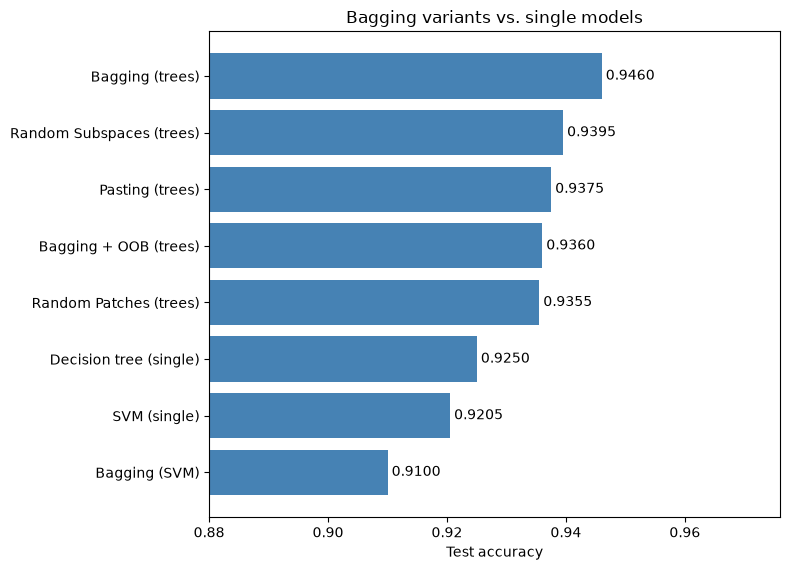

In [13]:
summary = pd.Series(results, name="test accuracy").sort_values()
print(summary.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 0.6 * len(summary) + 1))
bars = ax.barh(summary.index, summary.values, color="steelblue")
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_xlim(summary.min() - 0.03, min(1.0, summary.max() + 0.03))
ax.set_xlabel("Test accuracy")
ax.set_title("Bagging variants vs. single models")
plt.tight_layout()
plt.show()

## 9. Tips:

- Bagging usually beats pasting. Bootstrapping adds extra diversity between models and also gives you the OOB estimate for free.
- Good results typically come with **25%–50% row sampling** per model.
- Random subspaces and random patches are most useful for **high-dimensional data**.
- Bagging helps **high-variance** models (deep trees) much more than stable ones (SVMs, linear models).
- More estimators never overfit; they just cost time. Gains flatten out, so 100–200 trees are often enough.
- To find good hyperparameter values, use `GridSearchCV` or the cheaper `RandomizedSearchCV`.

## 10. Hyperparameter Tuning with GridSearchCV:

> **Heads-up:** this grid has 3 × 4 × 2 × 4 = **96 combinations**, and with 5-fold CV that is **480 ensemble fits**, so it can take a long time.
> Use `n_jobs=-1` and consider `RandomizedSearchCV(..., n_iter=20)` for a quicker search.

In [14]:
param_grid = {
    "n_estimators": [50, 100, 500],
    "max_samples": [0.1, 0.4, 0.7, 1.0],
    "bootstrap": [True, False],
    "max_features": [0.1, 0.4, 0.7, 1.0],
}

In [15]:
search = GridSearchCV(
    BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=RANDOM_STATE),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
)

In [16]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",BaggingClassi...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'bootstrap': [True, False], 'max_features': [0.1, 0.4, ...], 'max_samples': [0.1, 0.4, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_aut

In [17]:
print("Best params:  ", search.best_params_)
print(f"Best CV score: {search.best_score_:.4f}")

Best params:   {'bootstrap': True, 'max_features': 0.7, 'max_samples': 1.0, 'n_estimators': 100}
Best CV score: 0.9519


The search refits the best configuration on the full training set (`refit=True` is the default), so it can be scored on the untouched test set directly:

In [18]:
best = search.best_estimator_
results["Bagging (GridSearchCV best)"] = accuracy_score(y_test, best.predict(X_test))
print(f"Test accuracy of best model: {results['Bagging (GridSearchCV best)']:.4f}")

Test accuracy of best model: 0.9510
